# Quickstart: loading the GWHS dataset and running a model

The goal of this example is to:

1. check if the GPU access works,
2. load the GWHS sample dataset from Hugging Face (`GlobalWheat/GWHS_v1.0_sample`),
3. load a Global Wheat segmentation model from Hugging Face (`GlobalWheat/GWFSS_Segformer_b4`),
4. run the model on the GPU and plot its output.

It can be run with **Run → Run All Cells**. The first run downloagwhs the dataset and the model, so it may take up to a few minutes.

## 1. Check GPU access

In [6]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU found: {gpu.name} ({gpu.total_memory / 1e9:.0f} GB)")
else:
    device = torch.device("cpu")
    print("No GPU found, running on the CPU!")

GPU found: NVIDIA A10-8Q (8 GB)


## 2. Inspect the dataset

In [7]:
import pandas as pd
from datasets import load_dataset
from pprint import pprint

DATASET = "GlobalWheat/GWHS_v1.0_sample"
gwhs = load_dataset(DATASET, split="train")

categories = gwhs.features["objects"].feature["category"].names
print(categories)

# how many spikelets in each image?
spikelets = [len([obj for obj in row["objects"] if obj["category"] != categories.index("peduncle")]) for row in gwhs]

df = pd.DataFrame(
    {
        "image_id": gwhs["image_id"],
        "width": gwhs["width"],
        "height": gwhs["height"],
        "spikelets": spikelets,
    }
)
print(f"{len(df)} images:")
df

['peduncle', 'spikelet _-_underdeveloped_side1', 'spikelet _-_underdeveloped_side2', 'spikelet_-_side1', 'spikelet_-_side2', 'spikelet_-_terminal']
10 images:


,image_id,width,height,spikelets
0,149_ear_001.JPG,592,2509,23
1,21_11_2_7.jpg,1072,3044,24
2,252438_25R61_1_1_10DAI.png,1183,2576,12
3,B191-2_ear_000.png,1478,1366,15
4,crop_49-Sony-D2-BTH-3-REP2_14_JPG.rf.a7b159463...,347,774,19
5,DQ230105-023-07e_ear_003.png,1303,2357,21
6,DSC01469.JPG,1063,3572,19
7,GES23Del_170_picture_1_2023-06-26-04-32-43_ear...,247,547,21
8,MONTANS_LITERAL_BLE_2025-06-13_crop_08411_bee6...,624,620,21
9,Thatcher_R1_plot_15.4.jpg,1601,4263,15


## 3. Load the model

In [8]:
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation

MODEL = "GlobalWheat/GWFSS_Segformer_b4"

processor = AutoImageProcessor.from_pretrained(MODEL)
model = SegformerForSemanticSegmentation.from_pretrained(MODEL).to(device).eval()

labels = [model.config.id2label[i] for i in range(model.config.num_labels)]
print(f"Loaded {MODEL} on {next(model.parameters()).device}; classes: {labels}")

Loading weights: 100%|██████████| 930/930 [00:00<00:00, 5446.59it/s]


Loaded GlobalWheat/GWFSS_Segformer_b4 on cuda:0; classes: ['background', 'head', 'stem', 'leaf']


## 4. Run inference

In [9]:
import time
import numpy as np
import torch.nn.functional as F

predictions = []
start = time.perf_counter()
with torch.inference_mode():
    for row in gwhs:
        image = row["image"].convert("RGB")
        inputs = processor(images=image, return_tensors="pt").to(device)
        logits = model(**inputs).logits
        logits = F.interpolate(logits, size=(image.height, image.width), mode="bilinear", align_corners=False)
        predictions.append(logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8))
if device.type == "cuda":
    torch.cuda.synchronize()
print(f"Segmented {len(predictions)} images on {device} in {time.perf_counter() - start:.1f} s")

# add predictions to the df
for k, label in enumerate(labels):
    df[f"{label} (%)"] = [round(100 * float((p == k).mean()), 1) for p in predictions]
    
df

Segmented 10 images on cuda in 1.2 s


,image_id,width,height,spikelets,background (%),head (%),stem (%),leaf (%)
0,149_ear_001.JPG,592,2509,23,90.4,8.5,0.1,1.0
1,21_11_2_7.jpg,1072,3044,24,86.0,10.9,2.5,0.6
2,252438_25R61_1_1_10DAI.png,1183,2576,12,81.7,12.4,1.9,4.0
3,B191-2_ear_000.png,1478,1366,15,43.3,5.8,0.3,50.6
4,crop_49-Sony-D2-BTH-3-REP2_14_JPG.rf.a7b159463...,347,774,19,15.5,25.4,1.0,58.0
5,DQ230105-023-07e_ear_003.png,1303,2357,21,29.4,26.5,1.1,42.9
6,DSC01469.JPG,1063,3572,19,84.5,12.4,1.4,1.7
7,GES23Del_170_picture_1_2023-06-26-04-32-43_ear...,247,547,21,0.2,42.7,3.8,53.4
8,MONTANS_LITERAL_BLE_2025-06-13_crop_08411_bee6...,624,620,21,1.2,9.4,2.6,86.9
9,Thatcher_R1_plot_15.4.jpg,1601,4263,15,86.9,12.5,0.6,0.0


## 5. View the output

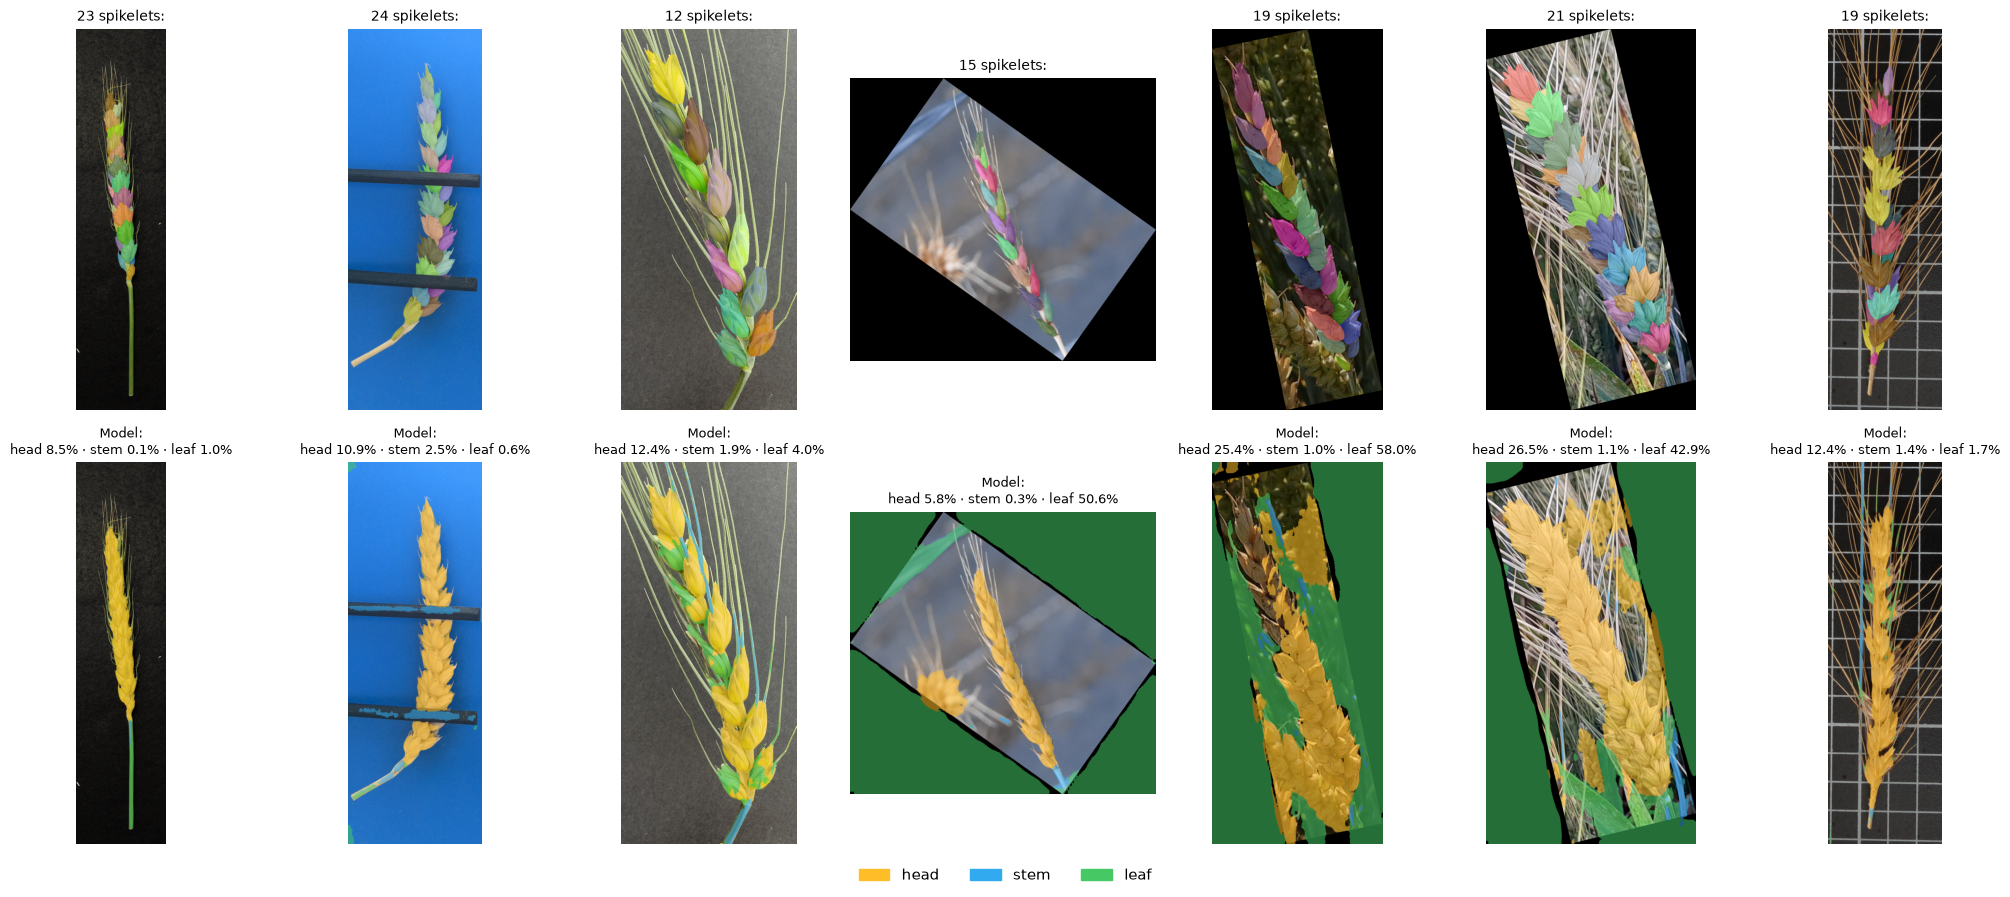

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pycocotools import mask as coco_mask

colors = np.array([[0, 0, 0], [255, 190, 40], [50, 170, 240], [70, 200, 100]], dtype=np.uint8)
rng = np.random.default_rng(42)

def color_spikelets(row):
    """Colors the spikelets randomly."""
    image = np.asarray(row["image"].convert("RGB")).copy()
    for obj in row["objects"]:
        if obj["category"] != categories.index("peduncle"):
            rle = {"size": obj["rle"]["size"], "counts": obj["rle"]["counts"].encode()}
            mask = coco_mask.decode(rle).astype(bool)
            image[mask] = (0.5 * image[mask] + 0.5 * rng.integers(0, 255, 3)).astype(np.uint8)
    return image


def model_output(row, prediction):
    """Colors by the head, stem and leaf predictions."""
    image = np.asarray(row["image"].convert("RGB")).copy()
    colored = prediction != 0
    image[colored] = (0.45 * image[colored] + 0.55 * colors[prediction[colored]]).astype(np.uint8)
    return image

# how many images to display
images = range(7)

fig, axes = plt.subplots(2, len(images), figsize=(3 * len(images), 9))
for col, i in enumerate(images):
    row = gwhs[i]
    axes[0, col].imshow(color_spikelets(row))
    axes[0, col].set_title(f"{df.iloc[i]["spikelets"]} spikelets:", fontsize=10)
    axes[1, col].imshow(model_output(row, predictions[i]))
    axes[1, col].set_title(f"Model:\nhead {df['head (%)'][i]}% · stem {df['stem (%)'][i]}% · leaf {df['leaf (%)'][i]}%",
        fontsize=9,)
for ax in axes.flat:
    ax.axis("off")

legend = [Patch(color=colors[k] / 255, label=labels[k]) for k in range(1, len(labels))]
fig.legend(handles=legend, loc="lower center", ncol=len(legend), frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Done!

Now you can pause or shut the session down. Please remember to commit and push your changes.   
Paused sessions are automatically shut down and deleted after some time.